# E10 · Small track (≤ 1M parameters): MobileNetV3-Small

The first model for the **≤ 1M track**. Everything is the `E09a` setup (12 bands, `hist_split`, contrast augmentation,
pseudo-labels round 3 from the single teacher `E06c` + AdaBN, Kaggle images 2× per epoch, AdaBN balanced at the end);
only the network changes.

| Variant | Network | Parameters | ImageNet weights |
|---|---|---|---|
| E09a (reference, medium track) | EfficientNet-B0 | 4.02M | yes |
| **E10a** | MobileNetV3-Small, head = one linear layer | 0.93M | yes |

**Why MobileNetV3-Small.** It is the only torchvision network with ImageNet weights that fits under 1M. The standard
head (576 → 1024 → classes) alone has about 0.6M parameters (1.53M in total), so it is replaced by one linear layer
on the pooled features, as for EfficientNet-B0. It has BatchNorm, so AdaBN works the same way.

**Same pseudo-labels as E09a** (teacher `E06c`, 8-view agreement), not labels or soft targets from E09a: the
teacher question (may a bigger model train the small one?) is not settled yet, see the single-model rule.

**Train or load.** `LOAD_RUNS` points every variant to its saved run. `None` = train again (about 10 minutes on an M4
GPU; creates new run folders).

## 1 · Setup and data

In [1]:
import json
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (add_pseudo_labels, class_mix, compare_variants, find_run, finish_run, kaggle_monitor,
                            kaggle_score, load_experiment_data, load_saved_model, plot_class_mix,
                            plot_variant_curves, select_view_agree, teacher_predictions, view_agreement)
from src.models import SMALL_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import Normalizer, TrainConfig, fit, load_run, predict_views
from src.utils import describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E10_small_track"
LOAD_RUNS = {   # saved runs; None = train this variant again
    "E10a": "runs/2026-10-24_2328_pl_r3_view_agree_contrast_aug_hist_split_mnv3s",
}
TEACHER = "adabn_balanced_pseudo_label_r2_x2_contrast_aug_hist_split_effb0"   # E06c + AdaBN, 71.50%
CAPS = {"SeaLake": 400}        # random subset of the agreeing images; other classes: all
REPEAT = 2                     # Kaggle images per epoch, as in E06c
REFERENCE = "adabn_balanced_pl_r3_view_agree_contrast_aug_hist_split_effb0"   # E09a + AdaBN, 71.78% (medium track)
MODEL = "mobilenet_v3_small"
BANDS = list(TEST_BANDS)
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})   # as in E09a
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))
results = {}                        # variant -> RunResult, compared at the end

data = load_experiment_data(BANDS, ["hist_split"], device)
print(data.summary())


def train_or_load(variant, tr_images, tr_labels):
    """Train on EuroSAT + pseudo-labels, or load the saved run."""
    if LOAD_RUNS[variant]:
        model, normalizer, history = load_saved_model(LOAD_RUNS[variant], device)
        return model, normalizer, history, None
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    model = build_model(MODEL, bands=BANDS, pretrained=True).to(device)
    history, best_state = fit(model, tr_images, tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))
    return model, normalizer, history, best_state


def base_config(variant, run_name, description, pseudo_labels):
    return {"run_name": run_name, "description": description, "notebook": NOTEBOOK, "variant": variant,
            "model": MODEL, "bands": BANDS, "corrections": ["hist_split"], "train": asdict(cfg),
            "split": "split_seed42", "pseudo_labels": pseudo_labels}

Device: Apple GPU (MPS)


train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


## 2 · Pseudo-labels (as in E09a)

`E06c` + AdaBN labels every Kaggle image (8 views averaged); all images whose 8 views agree are kept, SeaLake cut to
a random `CAPS`. Same seed and selection as E09a.

In [2]:
table, teacher_prob = teacher_predictions(TEACHER, data, device)
hard_idx = select_view_agree(table, CAPS, SEED)
print(f"{len(hard_idx):,} pseudo-labelled Kaggle images (E09a: 2,948)")
table.loc[hard_idx, "pred"].value_counts().reindex(CLASSES).to_frame("pseudo-labels")

2,948 pseudo-labelled Kaggle images (E09a: 2,948)


,pseudo-labels
pred,
AnnualCrop,300
Forest,362
HerbaceousVegetation,311
Highway,297
Industrial,224
Pasture,216
PermanentCrop,270
Residential,341
River,227


## 3 · E10a · MobileNetV3-Small

The parameter count is checked against `SMALL_TRACK_LIMIT` (1M) in `finish_run`.

In [3]:
tr_images, tr_labels, _ = add_pseudo_labels(data, table, hard_idx, repeat=REPEAT)
model, normalizer, history, best_state = train_or_load("E10a", tr_images, tr_labels)
results["E10a"] = finish_run(model, normalizer, history, best_state, data, variant="E10a", load_run=LOAD_RUNS["E10a"],
    device=device, seed=SEED, param_limit=SMALL_TRACK_LIMIT,
    config=base_config("E10a", "pl_r3_view_agree_contrast_aug_hist_split_mnv3s",
                       "MobileNetV3-Small (small track), E09a setup: hist_split + contrast aug + pseudo-labels round 3 (E06c teacher, 8 views agree), 2x",
                       {"teacher": TEACHER, "selection": "view_agree", "caps": CAPS, "repeat": REPEAT,
                        "n_images": int(len(hard_idx))}))
del tr_images, tr_labels

Pseudo-labelled Kaggle images: 2,948 of 4,232, used 2x (23.8% of the training set, 24,796 images)


epoch  1  train loss 1.719 acc 0.469  val loss 0.842 acc 0.725 *  val_conf 0.650  kg_conf 0.590  kg_sealake 0.243  kg_share_AnnualCrop 0.028  kg_share_Forest 0.206  kg_share_HerbaceousVegetation 0.091  kg_share_Highway 0.038  kg_share_Industrial 0.032  kg_share_Pasture 0.162  kg_share_PermanentCrop 0.069  kg_share_Residential 0.088  kg_share_River 0.043  kg_share_SeaLake 0.243  (20s)


epoch  2  train loss 0.839 acc 0.860  val loss 0.355 acc 0.903 *  val_conf 0.852  kg_conf 0.767  kg_sealake 0.244  kg_share_AnnualCrop 0.065  kg_share_Forest 0.177  kg_share_HerbaceousVegetation 0.078  kg_share_Highway 0.074  kg_share_Industrial 0.052  kg_share_Pasture 0.084  kg_share_PermanentCrop 0.091  kg_share_Residential 0.087  kg_share_River 0.047  kg_share_SeaLake 0.244  (18s)


epoch  3  train loss 0.708 acc 0.915  val loss 0.242 acc 0.946 *  val_conf 0.863  kg_conf 0.791  kg_sealake 0.241  kg_share_AnnualCrop 0.127  kg_share_Forest 0.099  kg_share_HerbaceousVegetation 0.118  kg_share_Highway 0.101  kg_share_Industrial 0.055  kg_share_Pasture 0.054  kg_share_PermanentCrop 0.063  kg_share_Residential 0.089  kg_share_River 0.052  kg_share_SeaLake 0.241  (18s)


epoch  4  train loss 0.661 acc 0.933  val loss 0.222 acc 0.952 *  val_conf 0.877  kg_conf 0.819  kg_sealake 0.243  kg_share_AnnualCrop 0.070  kg_share_Forest 0.071  kg_share_HerbaceousVegetation 0.172  kg_share_Highway 0.088  kg_share_Industrial 0.057  kg_share_Pasture 0.071  kg_share_PermanentCrop 0.079  kg_share_Residential 0.102  kg_share_River 0.047  kg_share_SeaLake 0.243  (18s)


...

epoch 17  train loss 0.534 acc 0.989  val loss 0.157 acc 0.978 *  val_conf 0.896  kg_conf 0.872  kg_sealake 0.241  kg_share_AnnualCrop 0.089  kg_share_Forest 0.102  kg_share_HerbaceousVegetation 0.104  kg_share_Highway 0.081  kg_share_Industrial 0.063  kg_share_Pasture 0.073  kg_share_PermanentCrop 0.096  kg_share_Residential 0.093  kg_share_River 0.059  kg_share_SeaLake 0.241  (19s)


epoch 18  train loss 0.532 acc 0.990  val loss 0.154 acc 0.978 *  val_conf 0.898  kg_conf 0.875  kg_sealake 0.241  kg_share_AnnualCrop 0.090  kg_share_Forest 0.104  kg_share_HerbaceousVegetation 0.100  kg_share_Highway 0.083  kg_share_Industrial 0.062  kg_share_Pasture 0.069  kg_share_PermanentCrop 0.097  kg_share_Residential 0.094  kg_share_River 0.059  kg_share_SeaLake 0.241  (19s)


epoch 19  train loss 0.531 acc 0.991  val loss 0.154 acc 0.978    val_conf 0.898  kg_conf 0.876  kg_sealake 0.241  kg_share_AnnualCrop 0.092  kg_share_Forest 0.104  kg_share_HerbaceousVegetation 0.102  kg_share_Highway 0.082  kg_share_Industrial 0.062  kg_share_Pasture 0.068  kg_share_PermanentCrop 0.095  kg_share_Residential 0.094  kg_share_River 0.059  kg_share_SeaLake 0.241  (19s)


epoch 20  train loss 0.531 acc 0.991  val loss 0.154 acc 0.978    val_conf 0.897  kg_conf 0.876  kg_sealake 0.241  kg_share_AnnualCrop 0.091  kg_share_Forest 0.102  kg_share_HerbaceousVegetation 0.104  kg_share_Highway 0.083  kg_share_Industrial 0.062  kg_share_Pasture 0.069  kg_share_PermanentCrop 0.096  kg_share_Residential 0.095  kg_share_River 0.058  kg_share_SeaLake 0.241  (20s)


E10a: internal test 98.02% · Kaggle confidence 86.6% (with AdaBN 79.8%) · 934,074 parameters
  run folders: runs/2026-10-24_2328_pl_r3_view_agree_contrast_aug_hist_split_mnv3s, runs/2026-10-24_2328_adabn_balanced_pl_r3_view_agree_contrast_aug_hist_split_mnv3s


## 4 · Comparison with E09a (same setup, EfficientNet-B0)

How much does the 4× smaller network lose, and where? Changes are split by the teacher's confidence: the uncertain
Kaggle images are where the vegetation pairs are.

In [4]:
ref_dir = find_run(REFERENCE)
r_model, r_norm, _ = load_run(ref_dir, device)
ref_views = predict_views(r_model, data.kg_images, r_norm)
ref_prob = ref_views.mean(0)
summary = compare_variants(results, reference=ref_prob, reference_name="E09a")
r_metrics = json.loads((find_run(REFERENCE.removeprefix("adabn_balanced_")) / "metrics.json").read_text())
summary.loc["E09a (medium track)"] = {"description": "EfficientNet-B0, 4.02M", "internal test (%)": r_metrics["internal_test_acc"] * 100,
                                      "confidence (%)": ref_prob.max(1).mean() * 100,
                                      "view agreement (%)": view_agreement(ref_views) * 100,
                                      "same class as E09a (%)": 100.0, "Kaggle public (%)": kaggle_score(ref_dir)}
for k, r in results.items():
    changed = r.prob_ada.argmax(1) != ref_prob.argmax(1)
    summary.loc[k, "differs: teacher unsure (%)"] = changed[table["conf"].values < 0.6].mean() * 100
    summary.loc[k, "differs: teacher confident (%)"] = changed[table["conf"].values >= 0.6].mean() * 100
summary.round(2)

,description,internal test (%),confidence (%),view agreement (%),same class as E09a (%),Kaggle public (%),differs: teacher unsure (%),differs: teacher confident (%)
E10a,"MobileNetV3-Small (small track), E09a setup: h...",98.024691,79.805786,86.862004,93.312854,None,44.57,2.17
E09a (medium track),"EfficientNet-B0, 4.02M",98.864198,85.016815,88.657845,100.0,71.782,NaN,NaN


In [5]:
# Different predictions: E09a's class (rows) -> E10a's class (columns)
ref_pred = np.array(CLASSES)[ref_prob.argmax(1)]
for k, r in results.items():
    new = np.array(CLASSES)[r.prob_ada.argmax(1)]
    changed = new != ref_pred
    print(f"{k}: {changed.sum()} images differ from E09a ({changed.mean():.1%})")
    display(pd.crosstab(ref_pred[changed], new[changed]).rename_axis(index="E09a", columns=k))

E10a: 283 images differ from E09a (6.7%)


E10a,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River
E09a,,,,,,,,,
AnnualCrop,0,3,1,6,1,1,18,1,0
Forest,0,0,22,1,0,6,2,2,4
HerbaceousVegetation,0,16,0,2,2,3,11,1,1
Highway,1,0,3,0,9,6,6,5,0
Industrial,0,0,2,5,0,1,7,4,1
Pasture,7,1,2,3,1,0,15,2,2
PermanentCrop,26,0,5,9,2,10,0,3,2
Residential,0,0,4,3,8,0,6,0,0
River,2,0,3,4,1,0,1,1,0


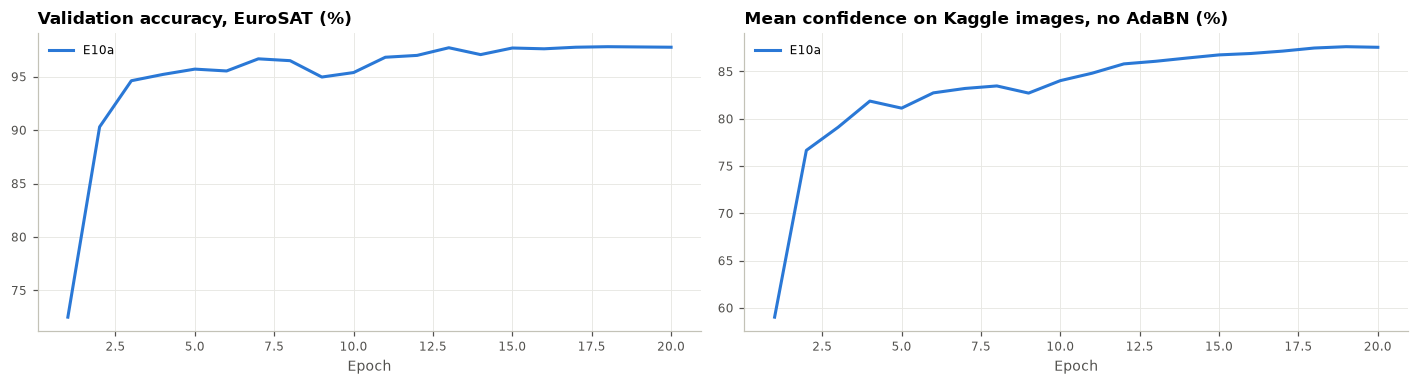

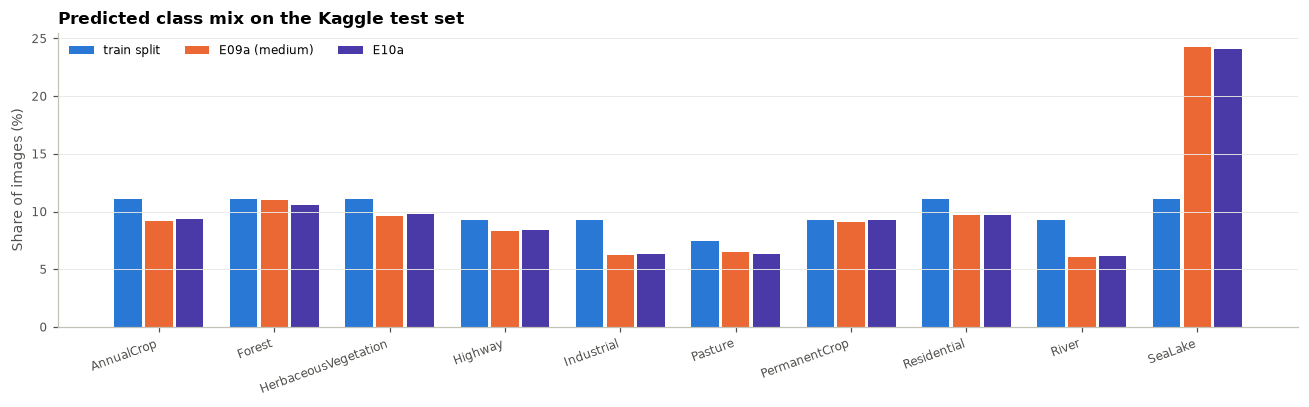

In [6]:
plot_variant_curves(results)
plot_class_mix(pd.DataFrame({"train split": class_mix(np.eye(10)[data.y_tr]), "E09a (medium)": class_mix(ref_prob),
                             **{k: class_mix(r.prob_ada) for k, r in results.items()}}))

## 5 · Conclusion

| Model | Parameters | Internal test | Kaggle confidence (no AdaBN → AdaBN) | View agreement | Same class as E09a | Kaggle public |
|---|---|---|---|---|---|---|
| E09a + AdaBN (medium track) | 4.02M | 98.86% | 87.4% → 85.0% | 88.7% | – | 71.78% |
| E10a + AdaBN | 0.93M | 98.02% | 86.6% → 79.8% | 86.9% | 93.3% | 70.61% |
| **E10a, no AdaBN** | **0.93M** | 98.02% | 86.6% | – | – | **70.94%** |

- **The small network fits easily and trains 3.5× faster** (18 s per epoch vs 65 s, 8 minutes in total). The best epoch is
  the 18th of 20, so it is not overfitting.
- **It loses 0.8 points on EuroSAT** (98.02% vs 98.86%) and agrees with E09a on 93.3% of the Kaggle images. The
  differences are where E09a is also unsure (44.6% of the images the teacher is unsure about, 2.2% of the confident
  ones), mostly the crop pairs (PermanentCrop ↔ AnnualCrop/Pasture, Forest ↔ HerbaceousVegetation).
- **AdaBN lowers its confidence much more than EfficientNet's** (−6.8 vs −2.4 points). MobileNetV3's BatchNorm
  statistics, together with its squeeze-excitation layers, seem more sensitive to the Kaggle statistics.
- **On Kaggle, AdaBN hurts the small model** (70.61% vs 70.94% without, −0.33). For EfficientNet it always helped. So the
  small-track model is E10a **without** AdaBN: **70.94%, only 0.84 points below the medium track** (71.78%) with 4.3×
  fewer parameters. The pseudo-labels already carry most of the Kaggle adaptation.

**Next:** knowledge distillation from E09a (ask the TAs first), or more epochs / a wider small network; test without
AdaBN by default.
